Formato da matriz: (2336, 3504, 3)
Número de dimensões: 3
Tipo de dados: uint8


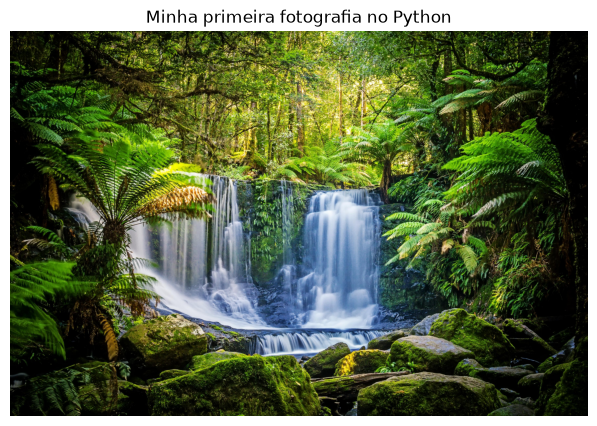

In [1]:

from PIL import Image
import numpy as np
import matplotlib.pyplot as plt

# Caminho da fotografia a partir da pasta notebooks
caminho = "../imagens/paisagem.jpg"

# Abrindo a fotografia e garantindo o formato RGB
foto = Image.open(caminho).convert("RGB")

# Convertendo a fotografia em uma matriz NumPy
imagem = np.array(foto)

# Informações da imagem
print("Formato da matriz:", imagem.shape)
print("Número de dimensões:", imagem.ndim)
print("Tipo de dados:", imagem.dtype)

# Exibindo a fotografia
plt.figure(figsize=(8, 5))
plt.imshow(imagem)
plt.title("Minha primeira fotografia no Python")
plt.axis("off")
plt.show()


In [2]:
# Consultando o primeiro pixel da fotografia
pixel = imagem[0, 0]

print("Primeiro pixel:", pixel)
print("Vermelho:", pixel[0])
print("Verde:", pixel[1])
print("Azul:", pixel[2])

Primeiro pixel: [5 5 3]
Vermelho: 5
Verde: 5
Azul: 3


In [3]:
# Calculando a posição central da fotografia
linha_central = imagem.shape[0] // 2
coluna_central = imagem.shape[1] // 2

# Consultando o pixel central
pixel_central = imagem[linha_central, coluna_central]

print("Posição:", linha_central, coluna_central)
print("RGB do centro:", pixel_central)

Posição: 1168 1752
RGB do centro: [ 62 111  55]



## Análise dos pixels da fotografia

A fotografia possui resolução de 3504 × 2336 pixels,
com três canais RGB e dados do tipo uint8.

### Primeiro pixel
- Posição: (0, 0)
- RGB: [5, 5, 3]
- Interpretação: cor muito próxima do preto.

### Pixel central
- Posição: (1168, 1752)
- RGB: [62, 111, 55]
- Interpretação: verde escuro, pois o canal verde
  possui a maior intensidade.

### Conclusão

Uma fotografia contém milhões de pixels, e cada
pixel RGB possui três valores numéricos.

Com NumPy, podemos acessar e analisar qualquer pixel
utilizando a posição da linha e da coluna.

A cor de um pixel não é suficiente, isoladamente,
para identificar o objeto presente na fotografia.


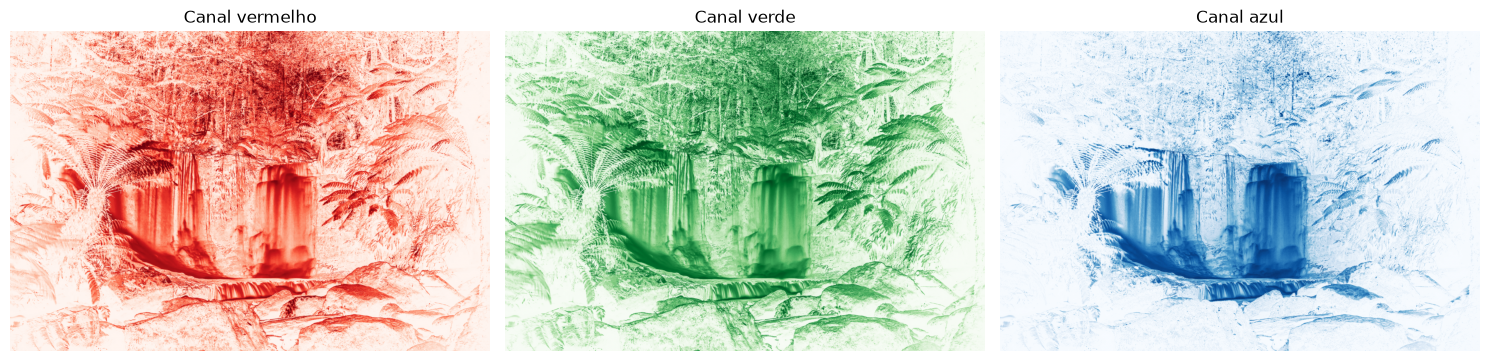

In [4]:

# Separando os canais RGB da fotografia
canal_vermelho = imagem[:, :, 0]
canal_verde = imagem[:, :, 1]
canal_azul = imagem[:, :, 2]

# Visualizando os três canais
fig, eixos = plt.subplots(1, 3, figsize=(15, 5))

eixos[0].imshow(canal_vermelho, cmap="Reds", vmin=0, vmax=255)
eixos[0].set_title("Canal vermelho")

eixos[1].imshow(canal_verde, cmap="Greens", vmin=0, vmax=255)
eixos[1].set_title("Canal verde")

eixos[2].imshow(canal_azul, cmap="Blues", vmin=0, vmax=255)
eixos[2].set_title("Canal azul")

for eixo in eixos:
    eixo.axis("off")

plt.tight_layout()
plt.show()


In [5]:
print("Média do vermelho:", canal_vermelho.mean())
print("Média do verde:", canal_verde.mean())
print("Média do azul:", canal_azul.mean())

Média do vermelho: 68.2372275374132
Média do verde: 82.54263803695972
Média do azul: 46.44747429063458



## Análise estatística dos canais RGB

Utilizando o método `mean()` do NumPy, calculamos
a intensidade média dos três canais da fotografia.

### Resultados

| Canal | Intensidade média |
|---|---:|
| Vermelho | 68,24 |
| Verde | 82,54 |
| Azul | 46,45 |

### Interpretação

O canal verde apresentou a maior intensidade média,
seguido pelo vermelho e pelo azul.

Esse resultado é compatível com a presença de vegetação
na fotografia analisada.

Entretanto, a média não informa a cor de cada pixel
individualmente nem identifica os objetos presentes.

### Conclusão

Aprendi que podemos utilizar estatística descritiva
para analisar imagens digitais.

O método `mean()` permite calcular a intensidade
média dos pixels de cada canal RGB.


Formato RGB: (2336, 3504, 3)
Formato cinza: (2336, 3504)


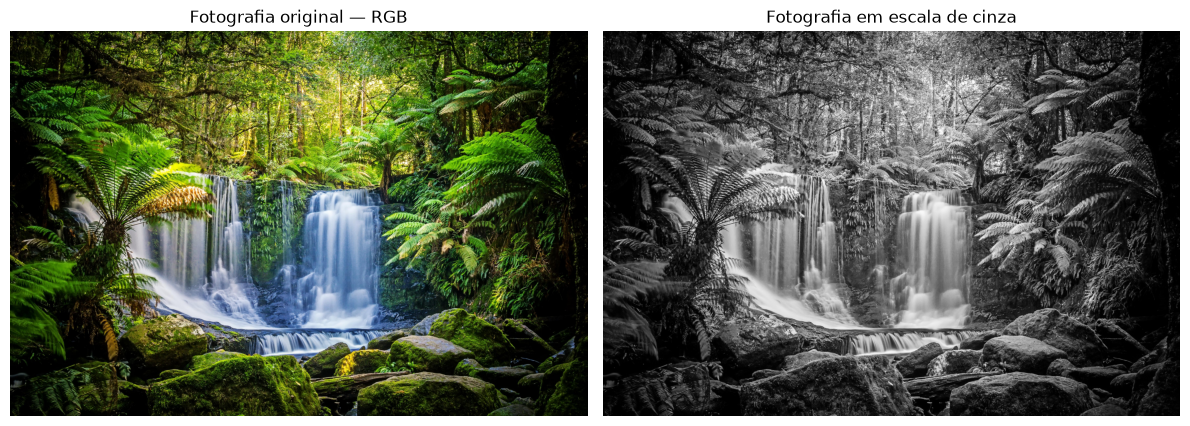

In [6]:

# Convertendo a fotografia RGB para escala de cinza
foto_cinza = foto.convert("L")

# Transformando em matriz NumPy
imagem_cinza = np.array(foto_cinza)

print("Formato RGB:", imagem.shape)
print("Formato cinza:", imagem_cinza.shape)

# Comparando as imagens
fig, eixos = plt.subplots(1, 2, figsize=(12, 5))

eixos[0].imshow(imagem)
eixos[0].set_title("Fotografia original — RGB")
eixos[0].axis("off")

eixos[1].imshow(imagem_cinza, cmap="gray", vmin=0, vmax=255)
eixos[1].set_title("Fotografia em escala de cinza")
eixos[1].axis("off")

plt.tight_layout()
plt.show()



## Conversão de RGB para escala de cinza

### Experimento

Utilizamos o método `convert("L")` da biblioteca
Pillow para transformar a fotografia colorida
em uma imagem em escala de cinza.

### Resultados

- Imagem RGB: `(2336, 3504, 3)`
- Imagem em escala de cinza: `(2336, 3504)`
- A altura e a largura foram preservadas.
- A imagem passou de três canais para uma matriz
  bidimensional de intensidades.

### Como funciona

A conversão considera diferentes contribuições
dos canais vermelho, verde e azul.

Uma aproximação da fórmula utilizada é:

Y = 0,299R + 0,587G + 0,114B

O canal verde possui maior peso no cálculo.

### Conclusão

Aprendi que uma imagem RGB pode ser convertida
em escala de cinza sem alterar sua resolução.

A conversão substitui os três valores RGB de
cada pixel por um único valor de intensidade.


In [7]:

# Recuperando o pixel central RGB
r, g, b = imagem[linha_central, coluna_central]

# Calculando manualmente a intensidade de cinza
cinza_calculado = (
    0.299 * int(r)
    + 0.587 * int(g)
    + 0.114 * int(b)
)

# Consultando o valor produzido pela Pillow
cinza_pillow = imagem_cinza[linha_central, coluna_central]

print("Pixel RGB:", [r, g, b])
print("Cinza calculado:", cinza_calculado)
print("Cinza Pillow:", cinza_pillow)


Pixel RGB: [np.uint8(62), np.uint8(111), np.uint8(55)]
Cinza calculado: 89.96499999999999
Cinza Pillow: 90



## Validação matemática da escala de cinza

### Pixel analisado

- Posição: (1168, 1752)
- RGB original: [62, 111, 55]

### Cálculo

Y = 0,299 × 62 + 0,587 × 111 + 0,114 × 55

**Resultado calculado:** 89,965

**Resultado da Pillow:** 90

### Observações

- O cálculo manual produziu um valor decimal.
- A Pillow armazenou um valor inteiro.
- Os resultados são compatíveis com o arredondamento.
- A representação 89.96499999999999 decorre da
  precisão numérica de ponto flutuante.

### Conclusão

Compreendi como os valores RGB contribuem para
a intensidade de cinza de um pixel.

Também aprendi a comparar um cálculo matemático
com o resultado produzido por uma biblioteca Python.


In [8]:
from pathlib import Path

caminho_saida = Path("../imagens/paisagem_cinza.png")

foto_cinza.save(caminho_saida)

print("Imagem salva em:", caminho_saida)
print("Arquivo existe:", caminho_saida.exists())

Imagem salva em: ..\imagens\paisagem_cinza.png
Arquivo existe: True
